# Titanic Survival Prediction

The goal is to predict which passengers survived and to find out which features matter most.

Steps: look at the data, make a simple rule as a baseline, build features, compare models with cross-validation, then pick one model for the Kaggle submission.

## 1. Setup and Data

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

In [2]:
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')

In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


## 2. Exploratory Analysis
Look for groups with very different survival rates. These ideas are used for the rule and the features later.

### What is the majority class of Survived?

In [5]:
train['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [6]:
actual = train['Survived']
prediction = np.zeros(len(train))
accuracy_score(actual, prediction)

0.6161616161616161

### Survived Rate by Sex

In [7]:
train.groupby('Sex')['Survived'].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

**Insight:** Female have a higher survival chance compared to male.

### Survival Rate by Pclass

In [8]:
train.groupby('Pclass', as_index=False)['Survived'].mean()

,Pclass,Survived
0,1,0.629630
1,2,0.472826
2,3,0.242363


### Survived data by Sex and Pclass

In [9]:
train.groupby(['Sex', 'Pclass'])['Survived'].agg(['mean', 'count'])

mean  count
Sex    Pclass                 
female 1       0.968085     94
       2       0.921053     76
       3       0.500000    144
male   1       0.368852    122
       2       0.157407    108
       3       0.135447    347

### Survival Rate by Title, create Title column

In [10]:
train['Title'] = train['Name'].str.split(',').str[1].str.split('.').str[0].apply(lambda x: x.strip())
test['Title'] = test['Name'].str.split(',').str[1].str.split('.').str[0].apply(lambda x: x.strip())
train.groupby(['Title'], as_index=False)['Survived'].agg(['mean', 'count'])

,Title,mean,count
0,Capt,0.000000,1
1,Col,0.500000,2
2,Don,0.000000,1
3,Dr,0.428571,7
4,Jonkheer,0.000000,1
5,Lady,1.000000,1
6,Major,0.500000,2
7,Master,0.575000,40
8,Miss,0.697802,182
9,Mlle,1.000000,2


**Insights:** Based on the count of these titles do grouping.

In [11]:
for df in [train, test]:
    df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    df['Title'] = df['Title'].where(df['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')

train.groupby('Title')['Survived'].agg(['mean', 'count'])

,mean,count
Title,,
Master,0.575000,40
Miss,0.702703,185
Mr,0.156673,517
Mrs,0.793651,126
Rare,0.347826,23


### Age Distribution by Survival

<Axes: xlabel='Age', ylabel='Count'>

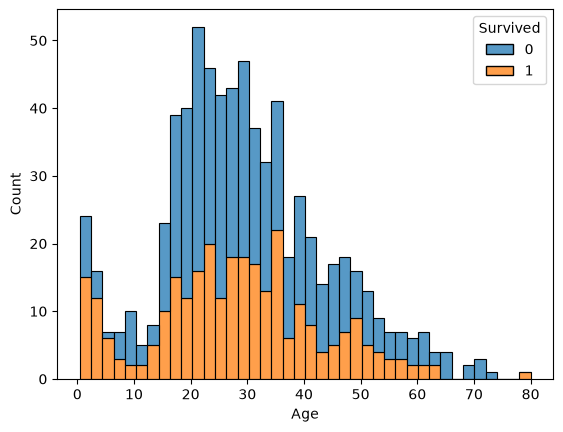

In [12]:
sns.histplot(data=train, x='Age', hue='Survived', bins = 40, multiple='stack')

**Insight:** Most passengers's age is between 20 and 36, but this group is too small which will shrinks the groups with other conditions.

### Survival Rate and Count by Embarked

In [13]:
train.groupby('Embarked')['Survived'].agg(['mean', 'count'])

,mean,count
Embarked,,
C,0.553571,168
Q,0.389610,77
S,0.336957,644


### Survived data by Sex, Pclass, and Embarked

In [14]:
train.groupby(['Sex', 'Pclass', 'Embarked'])['Survived'].agg(['mean', 'count'])

mean  count
Sex    Pclass Embarked                 
female 1      C         0.976744     43
              Q         1.000000      1
              S         0.958333     48
       2      C         1.000000      7
              Q         1.000000      2
              S         0.910448     67
       3      C         0.652174     23
              Q         0.727273     33
              S         0.375000     88
male   1      C         0.404762     42
              Q         0.000000      1
              S         0.354430     79
       2      C         0.200000     10
              Q         0.000000      1
              S         0.154639     97
       3      C         0.232558     43
              Q         0.076923     39
              S         0.128302    265

**Insight:** Passenger who is Female, Pclass is 1 or 2 is having a very high survival mean. Beside the female that embarked S, female in third class don't have a low survival mean compared to male.

## 3. Baseline: Rule-based Classifier

### Predict it with the patterns from the "Insight" above

In [15]:
actual = train['Survived']
prediction = ((train['Sex'] == 'female') & ~((train['Pclass'] == 3) & (train['Embarked'] == 'S'))).astype(int)

accuracy_score(actual, prediction)

0.8114478114478114

### Predict it with Female and first class

In [16]:
actual = train['Survived']
prediction = ((train['Sex'] == 'female') & (train['Pclass'] == 1)).astype(int)

accuracy_score(actual, prediction)

0.7149270482603816

**Insight:** The "Insight" patterns have a better accuracy score compared to this.

### Apply the patterns from "Insight" on the test dataframe as well

Rules applied: All the female besides those are both 3rd class and Embarked S.

In [17]:
test['Survived'] = ((test['Sex'] == 'female') & ~((test['Pclass'] == 3) & (test['Embarked'] == 'S'))).astype(int)


In [18]:
final_prediction = test[['PassengerId', 'Survived']]
final_prediction.head(10)

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


In [19]:
final_prediction.to_csv('ian_prediction.csv', index=False)

**Insight:** The rule( All the famle besides those are both 3rd class and Embarked S)'s score: 0.77844 is greater than the baseline(0.75). It built by hand from patterns I found.

## 4. Feature Engineering

I use four feature groups: sex and class, family size, travel groups and title. After that, a heatmap shows how much they overlap.

Age, Embarked, Cabin and Fare are not used. Age and Cabin have a lot of missing values, Embarked doesn't add much once we know the class, and Fare mostly repeats Pclass and the ticket group size.

### 1. Sex and Class
**Reason:** Sex and class work together. Almost all women in 1st and 2nd class survived, only about half of the women in 3rd class did, and men had low survival in every class. One flag for each combination lets the model use this directly.

In [20]:
def sex_class(df):
    X = pd.DataFrame(index=df.index)
    for sex in ['female', 'male']:
        for pclass in [1, 2, 3]:
            X[f'{sex}_{pclass}'] = ((df['Sex'] == sex) & (df['Pclass'] == pclass)).astype(int)
    return X

### 2. Family Size (with Alone and Large_Family)
**Reason:** Survival doesn't go up or down in a straight line with family size. Small families (2 to 4 people) did best, and people alone or in big families (5 or more) did worse, so the two flags mark both ends.

In [21]:
def family(df):
    X = pd.DataFrame(index=df.index)
    X['Fam_Size'] = df['SibSp'] + df['Parch'] + 1
    X['Alone'] = (X['Fam_Size'] == 1).astype(int)
    X['Large_Family'] = (X['Fam_Size'] >= 5).astype(int)
    return X

### 3. Travel Groups
**Reason:** People on the same ticket travelled together even if they weren't family (friends, maids, nannies), and SibSp/Parch miss them. I count the people on each ticket in train and test together to get the real group size. This doesn't use the Survived column, so there is no leakage.

In [22]:
ticket_counts = pd.concat([train['Ticket'], test['Ticket']]).value_counts()

def travel_group(df):
    X = pd.DataFrame(index=df.index)
    X['Group_Size'] = df['Ticket'].map(ticket_counts)
    X['Non_Family_Group'] = (X['Group_Size'] > df['SibSp'] + df['Parch'] + 1).astype(int)
    return X

### 4. Title
**Reason:** Title gives age and status information that the other features don't have. Master means a young boy, and boys survived much more than adult men. Mrs and Miss split married and unmarried women. Adding Title raised CV accuracy by about 3 points. The rare titles are left as the baseline group.

In [23]:
def title(df):
    X = pd.DataFrame(index=df.index)
    for t in ['Mr', 'Mrs', 'Miss', 'Master']:
        X['Title:' + t] = (df['Title'] == t).astype(int)
    return X

Combine the groups into the model input.

In [24]:
feature_groups = {
    'Sex x Class': sex_class,
    'Family Size': family,
    'Travel Groups': travel_group,
    'Title': title,
}

def preprocess(df, groups=feature_groups):
    return pd.concat([make(df) for make in groups.values()], axis=1)

X, y, X_test = preprocess(train), train['Survived'], preprocess(test)
print(X.shape, X_test.shape)
print('Missing values (train, test):', X.isnull().sum().sum(), X_test.isnull().sum().sum())
X.head()

(891, 15) (418, 15)
Missing values (train, test): 0 0


,female_1,female_2,female_3,male_1,male_2,male_3,Fam_Size,Alone,Large_Family,Group_Size,Non_Family_Group,Title:Mr,Title:Mrs,Title:Miss,Title:Master
0,0,0,0,0,0,1,2,0,0,1,0,1,0,0,0
1,1,0,0,0,0,0,2,0,0,2,0,0,1,0,0
2,0,0,1,0,0,0,1,1,0,1,0,0,0,1,0
3,1,0,0,0,0,0,2,0,0,2,0,0,1,0,0
4,0,0,0,0,0,1,1,1,0,1,0,1,0,0,0


### Feature correlation
Check how the features relate to each other and to Survived. If two features have a correlation close to 1 or -1, they hold almost the same information, and keeping both can make the model fit noise.

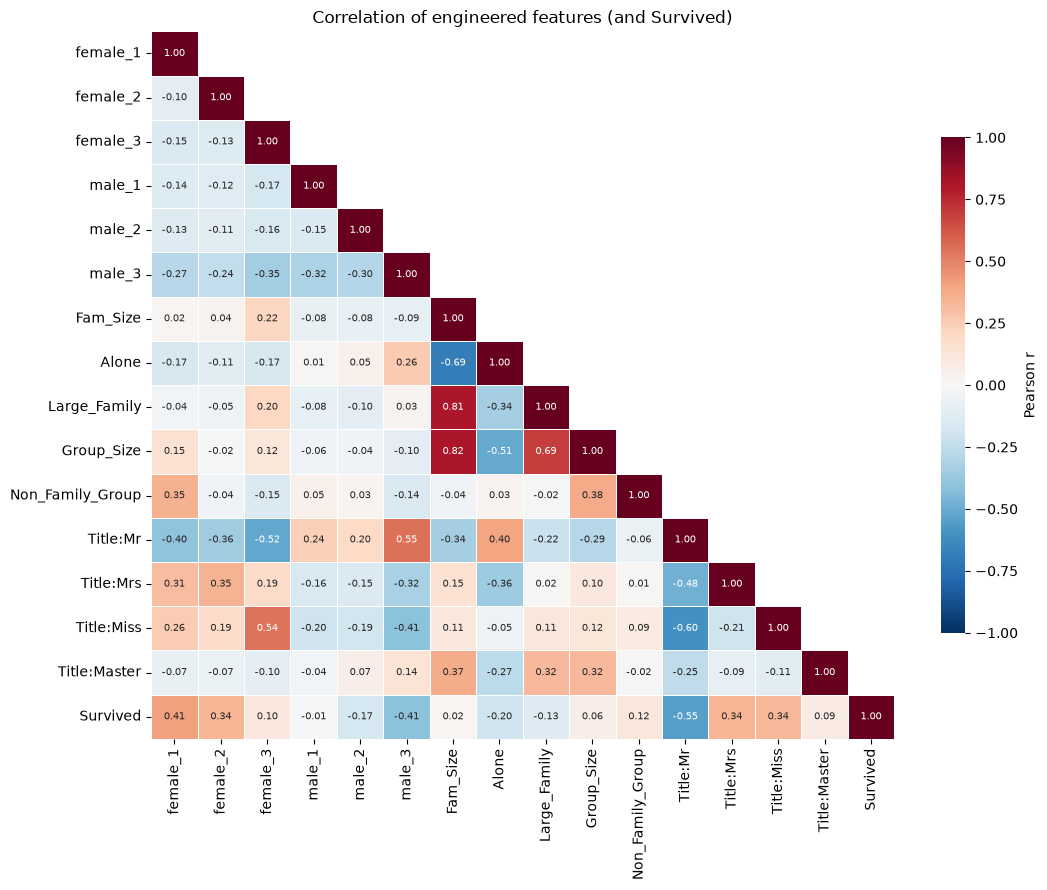

In [25]:
corr = pd.concat([X, y], axis=1).corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # show each pair once

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=0.5,
            cbar_kws={'shrink': 0.7, 'label': 'Pearson r'}, ax=ax)
ax.set_title('Correlation of engineered features (and Survived)')
plt.tight_layout()
plt.show()

**Insight:** The family features overlap the most. Fam_Size and Group_Size have 0.82, Fam_Size and Large_Family have 0.81, and Fam_Size and Alone have -0.69. Fam_Size alone has almost no linear relation with Survived (0.02), because survival goes up and then down as the family gets bigger. That's why I also split it into Alone and Large_Family. The strongest single features are Title:Mr (-0.55), female_1 (0.41) and male_3 (-0.41).

I also tried removing the overlapping features and adding a Child flag and a Rare title flag. CV only went up by 0.2 points and the Kaggle score went down (0.793 to 0.789 private), so I kept these features.

### Feature Group Test

Add one feature group at a time and score each step with 10x5 repeated stratified CV (50 fits for each bar), so an improvement has to show up across many splits and not just one lucky fold. The error bars are the standard deviation over the 50 folds.

In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
test_models = {
    'LogRe': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42),
}

group_names = list(feature_groups)
rows = []
for k in range(1, len(group_names) + 1):
    label = group_names[0] if k == 1 else '+ ' + group_names[k - 1]
    X_step = preprocess(train, {n: feature_groups[n] for n in group_names[:k]})
    for model_name, model in test_models.items():
        scores = cross_val_score(model, X_step, y, cv=rcv)
        rows.append({'step': label, 'model': model_name, 'n_features': X_step.shape[1],
                     'cv': scores.mean(), 'std': scores.std()})

group_results = pd.DataFrame(rows)
group_results

,step,model,n_features,cv,std
0,Sex x Class,LogRe,6,0.772960,0.023228
1,Sex x Class,Random Forest,6,0.773072,0.023116
2,+ Family Size,LogRe,9,0.799893,0.023543
3,+ Family Size,Random Forest,9,0.804492,0.026975
4,+ Travel Groups,LogRe,11,0.795289,0.025069
5,+ Travel Groups,Random Forest,11,0.803931,0.024808
6,+ Title,LogRe,15,0.828844,0.024360
7,+ Title,Random Forest,15,0.831878,0.023164


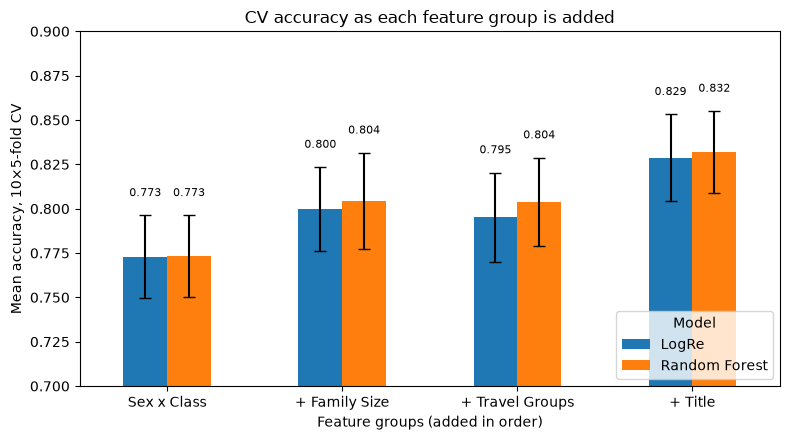

In [27]:
import matplotlib.pyplot as plt
from matplotlib.container import BarContainer

order = group_results['step'].unique()
means = group_results.pivot(index='step', columns='model', values='cv').loc[order]
stds = group_results.pivot(index='step', columns='model', values='std').loc[order]

ax = means.plot.bar(yerr=stds, capsize=4, rot=0, figsize=(8, 4.5))
for bars in ax.containers:
    if isinstance(bars, BarContainer):
        ax.bar_label(bars, fmt='%.3f', padding=12, fontsize=8)
ax.set_ylim(0.70, 0.90)
ax.set_xlabel('Feature groups (added in order)')
ax.set_ylabel('Mean accuracy, 10×5-fold CV')
ax.set_title('CV accuracy as each feature group is added')
ax.legend(title='Model', loc='lower right')
plt.tight_layout()
plt.show()

## 5. Modeling
Compare models on the same features. First a quick 5-fold CV, then 10x5 repeated CV when the scores are close. I also keep checking the gap between train and CV accuracy.

### Cross-validation setup

In [28]:
from sklearn.model_selection import cross_validate

results = {}
def evaluate(name, model):
    scores = cross_validate(model, X, y, cv=5, return_train_score=True)
    cv_acc = scores['test_score'].mean()
    gap = scores['train_score'].mean() - cv_acc
    results[name] = {'cv': cv_acc, 'gap': gap}
    print(name, 'cv:', round(cv_acc, 4), 'gap:', round(gap, 4))

cv is the average accuracy. Keeping tracking the gap(training accuracy - cv) to avoid overfitting.

### Base models

In [29]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

models_n = {
    'Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'LogRe': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'MLP': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(31, ), max_iter=1000, early_stopping=True, solver='adam', random_state=42))
}

for name, model in models_n.items():
    evaluate(name, model)

Tree cv: 0.8093 gap: 0.0406
LogRe cv: 0.8328 gap: -0.0017


MLP cv: 0.8148 gap: 0.007


**Insight:** Logistic Regression has the highest cv (0.833) and almost no gap. Decision Tree has the lowest cv and the biggest gap (0.041), so it overfits the most.

### Ensemble models

#### Simple combination (soft voting)

In [30]:
from sklearn.ensemble import VotingClassifier

voting_model = VotingClassifier(list(models_n.items()), voting='soft')
evaluate('Voting', voting_model)

Voting cv: 0.8238 gap: 0.0205


#### Bagging & Random Forest

In [31]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier

bagging_model = BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=6, random_state=42), n_estimators=200, random_state=42)

random_forest = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)

evaluate('Bagging', bagging_model)
evaluate('Random Forest', random_forest)

Bagging cv: 0.8227 gap: 0.0337


Random Forest cv: 0.8316 gap: 0.0104


#### Boosting

In [32]:
from sklearn.ensemble import AdaBoostClassifier

ada_model = AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=42)
evaluate('Ada_Boosted', ada_model)

Ada_Boosted cv: 0.8316 gap: 0.0006


#### Stacking

In [33]:
from sklearn.ensemble import StackingClassifier

stack_model = StackingClassifier(
    estimators=[
        ('LogRe', models_n['LogRe']),
        ('Random Forest', random_forest),
        ('MLP', models_n['MLP']),
        ('Ada_Boosted', ada_model)
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)

evaluate('Stacking', stack_model)

Stacking cv: 0.8316 gap: 0.0059


In [34]:
pd.DataFrame(results).T.sort_values('cv', ascending=False)

,cv,gap
LogRe,0.832754,-0.001667
Ada_Boosted,0.831630,0.000580
Random Forest,0.831624,0.010406
Stacking,0.831624,0.005917
Voting,0.823809,0.020467
Bagging,0.822685,0.033655
MLP,0.814795,0.007034
Tree,0.809271,0.040616


**Insight:** Stacking, Random Forest and AdaBoost tie at 0.832, a little behind Logistic Regression. The ensembles don't do better than a simple linear model with these features.

### L1 Logistic Regression with Interaction Terms

PolynomialFeatures with interaction_only=True multiplies every pair of features, so a linear model can use combinations like female_3 with Large_Family. The 15 features plus 105 pairs give 120 columns.

With l1_ratio=1.0 (lasso), many weights become exactly 0, so the model picks the useful pairs by itself. C is chosen with GridSearchCV using the 10x5 repeated CV.

In [35]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

pair_model = make_pipeline(
    PolynomialFeatures(degree=2, interaction_only=True, include_bias=False),
    StandardScaler(),
    LogisticRegression(l1_ratio=1.0, solver='liblinear', max_iter=5000),
)
search = GridSearchCV(pair_model, {'logisticregression__C': [0.03, 0.05, 0.1, 0.2, 0.5]}, cv=rcv, n_jobs=-1)
search.fit(X, y)
print('best C:', search.best_params_['logisticregression__C'], '| 10x5 cv:', round(search.best_score_, 4))

pair_model = search.best_estimator_
evaluate('L1 Pairs', pair_model)

best C: 0.1 | 10x5 cv: 0.832
L1 Pairs cv: 0.8328 gap: 0.0


The weights that are not 0 after the lasso fit, sorted by size. A positive weight means more likely to survive.

In [36]:
names = pair_model[0].get_feature_names_out(X.columns)
coef = pd.Series(pair_model[-1].coef_.ravel(), index=names)
kept = coef[coef != 0].sort_values(key=abs, ascending=False)
print(f'kept {len(kept)} of {len(coef)}')
kept.round(3)

kept 21 of 120


female_1                     0.798
male_3 Title:Mr             -0.605
Title:Mr                    -0.436
male_2                      -0.418
Large_Family Group_Size     -0.352
female_2                     0.295
Title:Master                 0.268
female_2 Fam_Size            0.230
Large_Family Title:Master   -0.228
male_2 Title:Master          0.208
Alone Group_Size             0.161
Large_Family                -0.090
male_2 Non_Family_Group     -0.087
male_1 Non_Family_Group     -0.067
female_2 Title:Miss          0.041
female_1 Large_Family        0.033
Alone Title:Mr              -0.032
Alone Title:Mrs              0.031
female_3 Large_Family       -0.022
male_2 Group_Size           -0.012
male_1 Title:Master          0.007
dtype: float64

In [37]:
pd.DataFrame(results).T.sort_values('cv', ascending=False)

,cv,gap
LogRe,0.832754,-0.001667
L1 Pairs,0.832754,0.000017
Ada_Boosted,0.831630,0.000580
Stacking,0.831624,0.005917
Random Forest,0.831624,0.010406
Voting,0.823809,0.020467
Bagging,0.822685,0.033655
MLP,0.814795,0.007034
Tree,0.809271,0.040616


#### Model comparison (10x5-fold CV)
All models use the same 15 features and the same 50 folds. Linear and ridge regression give a number instead of a class, so ThresholdRegressor turns it into 0 or 1 with a 0.5 cutoff.

In [38]:
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

class ThresholdRegressor(ClassifierMixin, BaseEstimator):
    """Use a regression model as a classifier: predict 1 when the output is >= 0.5."""
    def __init__(self, regressor):
        self.regressor = regressor
    def fit(self, X, y):
        self.regressor_ = clone(self.regressor).fit(X, y)
        self.classes_ = np.array([0, 1])
        return self
    def predict(self, X):
        return (self.regressor_.predict(X) >= 0.5).astype(int)

compare_models = {
    'L1 Interactions LogRe': pair_model,
    'Linear Regression (0.5 cutoff)': make_pipeline(StandardScaler(), ThresholdRegressor(LinearRegression())),
    'Ridge (0.5 cutoff)': make_pipeline(StandardScaler(), ThresholdRegressor(Ridge(alpha=10))),
    'LogRe (L2)': models_n['LogRe'],
    'Gradient Boosting (depth 2)': GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.1, random_state=42),
}

comparison = pd.DataFrame(
    {'CV accuracy': [cross_val_score(m, X, y, cv=rcv, n_jobs=-1).mean() for m in compare_models.values()]},
    index=pd.Index(list(compare_models), name='Model'),
)
comparison.style.format('{:.1%}')

,CV accuracy
Model,
L1 Interactions LogRe,83.2%
Linear Regression (0.5 cutoff),83.0%
Ridge (0.5 cutoff),83.1%
LogRe (L2),82.9%
Gradient Boosting (depth 2),83.0%


**Insight:** The L1 interaction model gets 83.2% with no gap between train and CV, and it only keeps 21 of the 120 columns. All five models are within 0.3 points of each other (82.9% to 83.2%), but adding feature groups changed accuracy by about 6 points (77.3% to 83.2%). Better features helped much more than a different model.

### Family Survival Rate Features + Per-Group Logistic Regression

Make a family ID (Family_Key) from surname and ticket. Train and test are combined, so a family split between the two files is still matched.

In [39]:
for df in [train, test]:
    df['Surname'] = df['Name'].str.split(',').str[0].str.strip()
    df['Family_Key'] = df['Surname'] + '_' + df['Ticket']
    df['Is_Boy'] = (df['Title'] == 'Master').astype(int)

info_cols = ['PassengerId', 'Family_Key', 'Sex', 'Pclass', 'Is_Boy']
X_fam = pd.concat([X, train[info_cols]], axis=1)
X_test_fam = pd.concat([X_test, test[info_cols]], axis=1)

family_sizes = pd.concat([train['Family_Key'], test['Family_Key']]).value_counts()
print('families with 2+ members:', (family_sizes >= 2).sum())

families with 2+ members: 176


New features, based on the other members of the same family who are in the training data:
- Family_Surv_Rate: the share of those members who survived, or -1 if none of them are in the training data.
- Family_Known: 1 if at least one other member is in the training data. This keeps "no information" separate from "nobody survived".
- Family_Surv_Smooth: (survivors + 1) / (members + 2). Small families are pulled toward 0.5, so a rate from more people counts for more.

To avoid leakage, these rates are rebuilt inside every CV fold using only that fold's training rows, and a passenger's own label is never used.

The model (SixGroupLR) fits a separate logistic regression for each Sex and Pclass group. Only the female 3rd class model uses Family_Surv_Smooth. The other five use Family_Surv_Rate.

In [40]:
class SixGroupLR(ClassifierMixin, BaseEstimator):
    """One logistic regression per Sex/Pclass group, with optional family survival features.

    Family survival only uses labels the model was fitted on, and never a passenger's own label,
    so CV scores are not leaked.
    """
    groups = [(s, p) for s in ['female', 'male'] for p in [1, 2, 3]]

    def __init__(self, family=True, smooth_groups=(('female', 3),), C=1.0):
        self.family = family
        self.smooth_groups = smooth_groups
        self.C = C

    def _family_features(self, X):
        known = self.known_
        totals = known.groupby('Family_Key')['Survived'].agg(['sum', 'count'])
        survivors = X['Family_Key'].map(totals['sum']).fillna(0)
        members = X['Family_Key'].map(totals['count']).fillna(0)
        own = X['PassengerId'].map(known.set_index('PassengerId')['Survived'])
        survivors = survivors - own.fillna(0)          # leave the passenger out
        members = members - own.notna()
        F = pd.DataFrame(index=X.index)
        F['Family_Surv_Rate'] = np.where(members > 0, survivors / members.clip(lower=1), -1)
        F['Family_Known'] = (members > 0).astype(int)
        F['Family_Surv_Smooth'] = (survivors + 1) / (members + 2)
        return F

    def _inputs(self, X, group):
        base = X.drop(columns=info_cols + list(sex_class(train).columns), errors='ignore')
        if not self.family:
            return base
        F = self._family_features(X)
        survival_col = 'Family_Surv_Smooth' if group in self.smooth_groups else 'Family_Surv_Rate'
        return pd.concat([base, F[[survival_col, 'Family_Known']]], axis=1)

    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        self.known_ = X[['PassengerId', 'Family_Key']].assign(Survived=y)
        self.classes_ = np.array([0, 1])
        self.models_ = {}
        for group in self.groups:
            mask = (X['Sex'] == group[0]) & (X['Pclass'] == group[1])
            if y[mask].nunique() < 2:                     # only one outcome seen: predict it
                self.models_[group] = int(y[mask].mode()[0]) if mask.any() else 0
                continue
            model = make_pipeline(StandardScaler(), LogisticRegression(C=self.C, max_iter=5000))
            self.models_[group] = model.fit(self._inputs(X[mask], group), y[mask])
        return self

    def predict(self, X):
        pred = pd.Series(0, index=X.index)
        for group, model in self.models_.items():
            mask = (X['Sex'] == group[0]) & (X['Pclass'] == group[1])
            if not mask.any():
                continue
            pred[mask] = model if isinstance(model, int) else model.predict(self._inputs(X[mask], group))
        return pred.to_numpy()

Score the per-group model with and without the family features, next to the earlier models, with the same 10x5 CV.

In [41]:
family_models = {
    'Per-group LogRe + family (smoothed F3)': (SixGroupLR(family=True), X_fam),
    'Per-group LogRe + family (raw rate)': (SixGroupLR(family=True, smooth_groups=()), X_fam),
    'Per-group LogRe, no family': (SixGroupLR(family=False), X_fam),
    'Decision Tree': (models_n['Tree'], X),
    'L1 Interactions LogRe': (pair_model, X),
}
family_results = pd.Series(
    {name: cross_val_score(model, data, y, cv=rcv, n_jobs=-1).mean() for name, (model, data) in family_models.items()},
    name='CV accuracy',
).sort_values()
family_results.map('{:.2%}'.format)

Per-group LogRe, no family                82.56%
Decision Tree                             82.58%
Per-group LogRe + family (raw rate)       83.12%
L1 Interactions LogRe                     83.20%
Per-group LogRe + family (smoothed F3)    83.59%
Name: CV accuracy, dtype: str

**Insight:** The family rates raise the per-group model from 82.6% to 83.1%, and the smoothed rate for 3rd class women brings it to 83.6%, the best CV in this notebook. That's only 0.4 points above the L1 interaction model, which is small compared to the about 2.4 point spread between folds.

### More models with the family features

The family rates helped the per-group model, so here I add them to many different models and compare them with the same 10x5 CV.

WithFamily is a small wrapper. Inside each fold it builds the family rates from that fold's training labels, adds Family_Surv_Smooth and Family_Known to the 15 features, and then fits the model.

I also test a simple women-child group rule. Men die. Women survive, unless every other woman or boy in their family who is in the training data died. Boys (title Master) die, unless every other woman or boy in their family survived.

In [42]:
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier

def family_rates(X, known):
    # survival of the other known members of each passenger's family
    totals = known.groupby('Family_Key')['Survived'].agg(['sum', 'count'])
    surv = X['Family_Key'].map(totals['sum']).fillna(0)
    n = X['Family_Key'].map(totals['count']).fillna(0)
    own = X['PassengerId'].map(known.set_index('PassengerId')['Survived'])
    surv, n = surv - own.fillna(0), n - own.notna()
    return pd.DataFrame({
        'Family_Surv_Rate': np.where(n > 0, surv / n.clip(lower=1), -1),
        'Family_Known': (n > 0).astype(int),
        'Family_Surv_Smooth': (surv + 1) / (n + 2),
    }, index=X.index)


class WithFamily(ClassifierMixin, BaseEstimator):
    # adds family rates (built from the training labels only) to any model
    def __init__(self, estimator, cols=('Family_Surv_Smooth', 'Family_Known')):
        self.estimator = estimator
        self.cols = cols

    def _inputs(self, X):
        return pd.concat([X.drop(columns=info_cols), family_rates(X, self.known_)[list(self.cols)]], axis=1)

    def fit(self, X, y):
        self.known_ = X[['PassengerId', 'Family_Key']].assign(Survived=np.asarray(y))
        self.classes_ = np.array([0, 1])
        self.model_ = clone(self.estimator).fit(self._inputs(X), y)
        return self

    def predict(self, X):
        return self.model_.predict(self._inputs(X))


class WomenChildGroup(ClassifierMixin, BaseEstimator):
    # gender rule, changed only when the woman/boy part of the family all lived or all died
    def fit(self, X, y):
        wc = ((X['Sex'] == 'female') | (X['Is_Boy'] == 1)).to_numpy()
        self.known_ = X.loc[wc, ['PassengerId', 'Family_Key']].assign(Survived=np.asarray(y)[wc])
        self.classes_ = np.array([0, 1])
        return self

    def predict(self, X):
        f = family_rates(X, self.known_)
        female, boy = X['Sex'] == 'female', X['Is_Boy'] == 1
        pred = female.astype(int)
        pred[female & (f['Family_Known'] == 1) & (f['Family_Surv_Rate'] == 0)] = 0
        pred[boy & (f['Family_Known'] == 1) & (f['Family_Surv_Rate'] == 1)] = 1
        return pred.to_numpy()

In [43]:
svm_family = WithFamily(make_pipeline(StandardScaler(), SVC(C=1.0)))
gb_family = WithFamily(GradientBoostingClassifier(n_estimators=150, max_depth=2, random_state=42))
vote_family = VotingClassifier([('svm', svm_family), ('wcg', WomenChildGroup()), ('gb', gb_family)], voting='hard')

many_models = {
    'L1 interactions, no family': (pair_model, X),
    'Women-child group rule': (WomenChildGroup(), X_fam),
    'LogRe + family': (WithFamily(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))), X_fam),
    'L1 interactions + family': (WithFamily(clone(pair_model)), X_fam),
    'Random Forest + family': (WithFamily(RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)), X_fam),
    'Extra Trees + family': (WithFamily(ExtraTreesClassifier(n_estimators=300, max_depth=6, random_state=42)), X_fam),
    'Gradient Boosting + family': (gb_family, X_fam),
    'KNN (k=15) + family': (WithFamily(make_pipeline(StandardScaler(), KNeighborsClassifier(15))), X_fam),
    'SVM (RBF) + family': (svm_family, X_fam),
    'Vote: SVM + rule + GB': (vote_family, X_fam),
}
many_results = pd.DataFrame(
    [(name, *(lambda s: (s.mean(), s.std()))(cross_val_score(m, data, y, cv=rcv, n_jobs=-1))) for name, (m, data) in many_models.items()],
    columns=['model', 'cv', 'std'],
).set_index('model').sort_values('cv', ascending=False)
many_results.round(4)

,cv,std
model,,
Vote: SVM + rule + GB,0.8427,0.0230
SVM (RBF) + family,0.8413,0.0228
Women-child group rule,0.8372,0.0256
Gradient Boosting + family,0.8365,0.0220
LogRe + family,0.8361,0.0238
L1 interactions + family,0.8355,0.0225
KNN (k=15) + family,0.8332,0.0234
Random Forest + family,0.8331,0.0241
"L1 interactions, no family",0.8320,0.0230


**Insight:** Adding the family rates helps almost every model, by about 0.5 to 1 point. The best single model is SVM with the family features (84.1%), and a simple vote of SVM, the women-child rule and gradient boosting is a little better (84.3%). The women-child rule alone gets 83.7% with no training at all, which shows how much of the signal is just sex plus what happened to the rest of the family. In CV each fold only knows about 80% of the family labels, but for the real test set all 891 are known, so the family rates have more to work with on Kaggle than in CV.

On Kaggle, all three saved candidates passed 0.80 on the private score (see the table in section 6).

Save one submission file for each of the three best ideas, so I can compare them on Kaggle.

In [44]:
candidates = {
    'ian_submission_vote.csv': vote_family,
    'ian_submission_svm_family.csv': svm_family,
    'ian_submission_wcg_rule.csv': WomenChildGroup(),
}
l1_pred = pair_model.fit(X, y).predict(X_test)
for file, model in candidates.items():
    pred = clone(model).fit(X_fam, y).predict(X_test_fam)
    pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': pred}).to_csv(file, index=False)
    print(f'{file:32s} survived: {pred.sum()}  different from L1 model: {(pred != l1_pred).sum()}')

ian_submission_vote.csv          survived: 155  different from L1 model: 15
ian_submission_svm_family.csv    survived: 158  different from L1 model: 12
ian_submission_wcg_rule.csv      survived: 154  different from L1 model: 14


## 6. Final Model for Submission

I submitted the three candidates to Kaggle and compared them with my earlier final model:

| Submission | CV (10x5) | Kaggle private | Kaggle public |
|---|---|---|---|
| Women-child group rule | 83.7% | 0.80478 | 0.77844 |
| Vote: SVM + rule + GB | 84.3% | 0.80478 | 0.77245 |
| SVM + family | 84.1% | 0.80079 | 0.76047 |
| L1 interactions, no family (old final) | 83.2% | 0.79282 | 0.76047 |

All three family models passed 0.80 on the private score. I picked the women-child group rule as the final model. It ties for the best private score, has the best public score, and it is the simplest one, since it doesn't need any training.

In [45]:
final_model = WomenChildGroup()
final_model.fit(X_fam, y)

final_submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': final_model.predict(X_test_fam)})
final_submission.to_csv('ian_final_prediction.csv', index=False)
final_submission['Survived'].value_counts()

Survived
0    264
1    154
Name: count, dtype: int64

## 7. Summary
- Predicting that everyone died gives 61.6%. My hand-written rule (women survive, except 3rd class women from Southampton) got 0.778 on Kaggle.
- The features did most of the work. With 10x5 CV, sex and class alone get 77.3%, family size brings it to about 80%, and Title to about 83%.
- Without family information, the model choice barely mattered. Linear, ridge, logistic, boosting and the L1 interaction model were all between 82.9% and 83.2%, and the best of them got 0.79282 on Kaggle.
- What other family members did was the missing piece. Adding family survival rates raised almost every model by 0.5 to 1 point in CV, and all three family submissions passed 0.80 on the private score.
- Final model: the women-child group rule, 0.80478 private and 0.77844 public. It's the simplest model in the notebook and it scored the best.
- Small CV differences didn't carry over to Kaggle. The vote had the best CV but tied the rule on private and was lower on public, so when scores are close I go with the simpler model.